# 芯片测试 2/3：良率、归因与晶圆图

**目标**：低良率到底是**测试系统（硬件）**的问题，还是**芯片/工艺（硅）**的问题？
方法是"同一个 lot 内对照"：同一批芯片被随机分到不同的测试机和 site，
所以只要某个 (测试机, site) 显著差于同 lot 其余部分，问题就更像出在测试系统上。

**输入**：Notebook 01 产出的 `data/processed/chip_parts.csv`、`chip_tests.csv`

**输出**：
- `reports/chip/c01`–`c05` 五张图（良率、热力图、晶圆图、径向良率、测试机参数分布）
- `data/processed/chip_summary.json` 的前半部分（整体良率、线索、集群晶圆、整批偏移的 lot）；
  Notebook 03 补全后半部分

与 Python 版（`chiptest/yield_analysis.py`、`attribution.py`、`parametric.py`、`wafer.py`）同一套算法，
由 `tests/test_chip_notebook_parity.py` 对照。

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import ndimage, stats

sns.set_theme(style="whitegrid")

cwd = Path.cwd()
ROOT = next((folder.parent for folder in (cwd, *cwd.parents) if folder.name == "notebooks"), cwd)
CLEAN = ROOT / "data" / "processed" / "chip_parts.csv"
TESTS = ROOT / "data" / "processed" / "chip_tests.csv"
SUMMARY = ROOT / "data" / "processed" / "chip_summary.json"
FIGURES = ROOT / "reports" / "chip"
FIGURES.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight")

## 1. 载入清洗后的数据

所有良率、归因都**以首测为单位**（每颗芯片一条）：复测会掩盖第一次失败，
而"第一次为什么失败"恰恰是归因要回答的问题。

In [2]:
if not (CLEAN.exists() and TESTS.exists()):
    raise FileNotFoundError("先运行 Notebook 01，生成 chip_parts.csv 与 chip_tests.csv")

df = pd.read_csv(CLEAN, parse_dates=["test_time", "date"], dtype={"wafer_id": str, "part_id": str})
tests = pd.read_csv(TESTS)
first = df[df["is_first_pass"]]
test_names = list(tests["name"])
cont = list(tests.loc[tests["unit"] != "cnt", "name"])
print(f"{len(df):,} 条记录 -> {len(first):,} 颗芯片（首测），{first['lot_id'].nunique()} 个 lot，")
print(f"{first['station'].nunique()} 台测试机，每台 {first['site'].nunique()} 个 site")

77,265 条记录 -> 71,907 颗芯片（首测），8 个 lot，
3 台测试机，每台 4 个 site


## 2. 三个良率口径，不要混

- **FPY（首测良率）**：首测一次通过 / 首测芯片数。同时反映芯片和测试系统。
- **最终良率**：复测之后的最终判定，是出货口径。
- **复测恢复率**：首测失败且被复测的芯片里，最终通过的比例。恢复率高，说明失败是**间歇性**的
  （接触、噪声、裕量边缘），而不是芯片本身坏了——这是区分"硬件问题"和"真缺陷"的第一条线索。

In [3]:
def yield_by(first, by):
    failed = ~first["tester_pass"]
    frame = first.assign(
        failed=failed,
        retested_fail=failed & first["retested"],
        recovered=failed & first["retested"] & first["final_ok"],
    )
    out = frame.groupby(by, observed=True).agg(
        dies=("x", "size"),
        passed=("tester_pass", "sum"),
        final_passed=("final_ok", "sum"),
        retested=("retested_fail", "sum"),
        recovered=("recovered", "sum"),
    )
    out["fpy"] = out["passed"] / out["dies"]
    out["final_yield"] = out["final_passed"] / out["dies"]
    out["recovery_rate"] = out["recovered"] / out["retested"].replace(0, np.nan)
    return out.reset_index()


def overall(first):
    row = yield_by(first.assign(scope="all"), "scope").iloc[0]
    return {
        "dies": int(row["dies"]),
        "fpy": float(row["fpy"]),
        "final_yield": float(row["final_yield"]),
        "retested": int(row["retested"]),
        "recovery_rate": float(row["recovery_rate"]),
    }


overall_yield = overall(first)
print(
    f"整体：{overall_yield['dies']:,} 颗，FPY {overall_yield['fpy']:.2%}，"
    f"最终良率 {overall_yield['final_yield']:.2%}，"
    f"首测失败后被复测的 {overall_yield['retested']:,} 颗里恢复了 {overall_yield['recovery_rate']:.1%}"
)
by_lot = yield_by(first, "lot_id")
by_lot.round(4)

整体：71,907 颗，FPY 92.54%，最终良率 93.20%，首测失败后被复测的 5,348 颗里恢复了 8.8%


,lot_id,dies,passed,final_passed,retested,recovered,fpy,final_yield,recovery_rate
0,L01,8992,8504,8528,486,24,0.9457,0.9484,0.0494
1,L02,8986,8528,8547,456,19,0.9490,0.9511,0.0417
2,L03,8986,8444,8464,541,20,0.9397,0.9419,0.0370
3,L04,8979,8317,8469,661,152,0.9263,0.9432,0.2300
4,L05,8989,8255,8304,731,49,0.9183,0.9238,0.0670
5,L06,8993,8329,8465,663,136,0.9262,0.9413,0.2051
6,L07,8995,7940,7973,1053,33,0.8827,0.8864,0.0313
7,L08,8987,8228,8268,757,40,0.9155,0.9200,0.0528


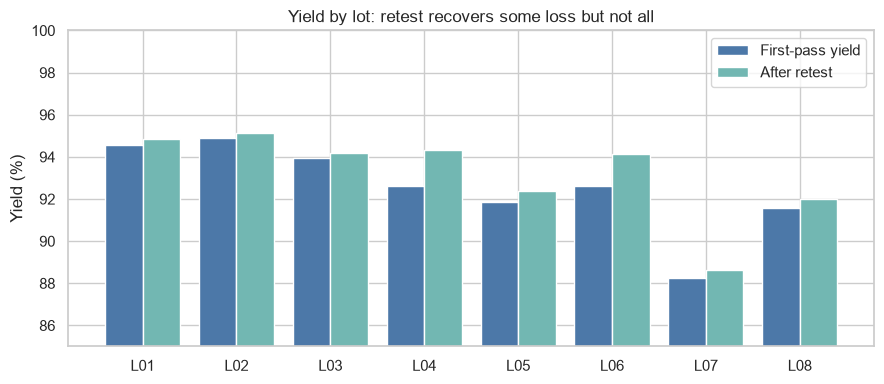

In [4]:
x = np.arange(len(by_lot))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.2, by_lot["fpy"] * 100, 0.4, label="First-pass yield", color="#4C78A8")
ax.bar(x + 0.2, by_lot["final_yield"] * 100, 0.4, label="After retest", color="#72B7B2")
ax.set_xticks(x, by_lot["lot_id"])
ax.set_ylim(min(by_lot["fpy"].min() * 100 - 3, 85), 100)
ax.set_ylabel("Yield (%)")
ax.set_title("Yield by lot: retest recovers some loss but not all")
ax.legend(loc="upper right")
save(fig, "c01_yield_by_lot.png")

首测良率和复测后良率之间的差距，就是"复测挽回"的部分，两个口径的差别要看恢复率：

- L04、L06 的恢复率明显高（约 23%、21%，其余 lot 只有 3%–7%）：失败有一大块是间歇性的，不是芯片坏了；
- L07 的 FPY 最低，但恢复率只有 3%：复测几乎帮不上忙，失败是稳定可复现的。

这些都只是**现象**，下一步要把它们拆到具体的测试机和 site 上，再解释为什么。

In [5]:
fails = first[~first["tester_pass"]]
bin_pareto = fails.groupby(["hbin", "hbin_name"]).size().rename("dies").reset_index()
bin_pareto = bin_pareto.sort_values("dies", ascending=False).reset_index(drop=True)
bin_pareto["share_of_fails"] = bin_pareto["dies"] / bin_pareto["dies"].sum()
bin_pareto["cumulative"] = bin_pareto["share_of_fails"].cumsum()
bin_pareto.round(3)

,hbin,hbin_name,dies,share_of_fails,cumulative
0,3,LEAKAGE,1545,0.288,0.288
1,6,SPEED,1245,0.232,0.520
2,7,MEMORY,963,0.180,0.700
3,8,FUNCTIONAL,876,0.163,0.863
4,5,ANALOG,535,0.100,0.963
5,2,CONTACT,189,0.035,0.998
6,4,POWER,9,0.002,1.000


## 3. 是测试硬件的问题，还是芯片的问题？

对每个分组，把它的 FPY 和**同 lot 其余芯片**比，用 Fisher 精确检验衡量差异。
样本一大，任何微小差异的 p 值都极小，所以同时要求**实际影响**（FPY 至少低 3 个百分点），
只有"统计显著 + 有实际影响"才算热点。

In [6]:
def peer_hotspots(first, by):
    table = yield_by(first, by)
    lot_total = first.groupby("lot_id").agg(n=("x", "size"), p=("tester_pass", "sum"))
    rows = []
    for _, row in table.iterrows():
        n_all, p_all = lot_total.loc[row["lot_id"], ["n", "p"]]
        n_rest, p_rest = int(n_all - row["dies"]), int(p_all - row["passed"])
        _, p_value = stats.fisher_exact(
            [
                [int(row["passed"]), int(row["dies"] - row["passed"])],
                [p_rest, n_rest - p_rest],
            ]
        )
        rows.append((p_rest / n_rest, p_value))
    table[["rest_fpy", "fisher_p"]] = rows
    table["delta"] = table["fpy"] - table["rest_fpy"]
    return table


def flag_hotspots(table, p_max=1e-6, min_drop=0.03):
    hit = table[(table["fisher_p"] < p_max) & (table["delta"] <= -min_drop)]
    return hit.sort_values("fisher_p").reset_index(drop=True)


cells = flag_hotspots(peer_hotspots(first, ["lot_id", "station", "site"]))
stations = flag_hotspots(peer_hotspots(first, ["lot_id", "station"]))
columns = ["lot_id", "station", "site", "dies", "fpy", "rest_fpy", "delta", "fisher_p"]
print("(lot, 测试机, site) 级热点：")
display(cells[columns].round(4))
print("(lot, 测试机) 级热点：")
display(stations[[c for c in columns if c != "site"]].round(4))

(lot, 测试机, site) 级热点：


,lot_id,station,site,dies,fpy,rest_fpy,delta,fisher_p
0,L04,T02,3,687,0.6638,0.9480,-0.2843,0.0
1,L05,T01,1,899,0.8387,0.9272,-0.0885,0.0
2,L05,T01,2,916,0.8624,0.9247,-0.0622,0.0
3,L08,T01,1,898,0.8597,0.9217,-0.0621,0.0
4,L08,T01,3,919,0.8683,0.9209,-0.0526,0.0


(lot, 测试机) 级热点：


,lot_id,station,dies,fpy,rest_fpy,delta,fisher_p
0,L05,T01,3594,0.8720,0.9492,-0.0772,0.0
1,L08,T01,3595,0.8729,0.9440,-0.0711,0.0
2,L04,T02,2693,0.8763,0.9477,-0.0713,0.0


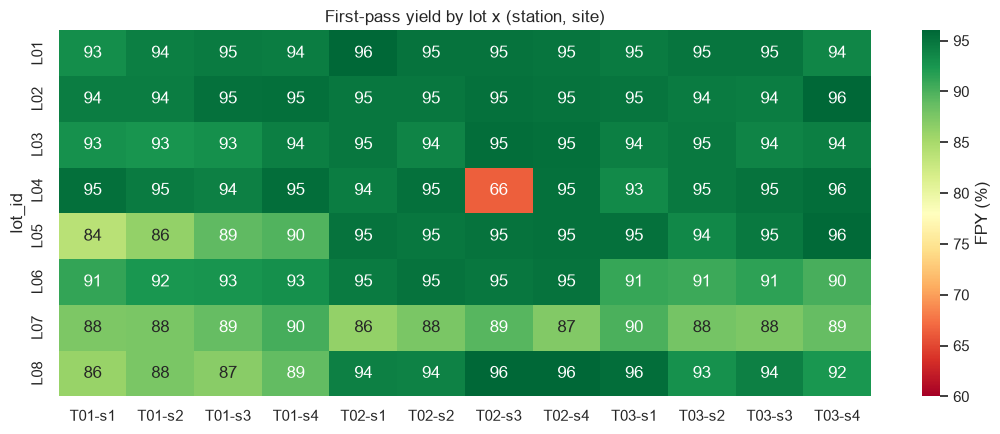

In [7]:
grid = (
    first.assign(cell=first["station"] + "-s" + first["site"].astype(str))
    .pivot_table(index="lot_id", columns="cell", values="tester_pass", aggfunc="mean")
    .mul(100)
)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(
    grid,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn",
    vmin=60,
    vmax=96,
    ax=ax,
    cbar_kws={"label": "FPY (%)"},
)
ax.set_title("First-pass yield by lot x (station, site)")
ax.set_xlabel("")
save(fig, "c02_fpy_heatmap_station_site.png")

热力图一眼能看出最异常的格子。但一个格子"差"还不够，
要继续判断它是**单个 site 的接触问题**，还是**整台测试机的电源/时序问题**，
这需要看参数分布，而不只是良率。

## 4. 测试机之间的参数对比：噪声 vs 偏移

三条纪律：

1. 全程用**稳健统计**（中位数 + MAD，σ ≈ 1.4826·MAD），不用均值和标准差。致命缺陷芯片的读数极端，会把均值和标准差拉偏。
2. 比较要在**同一个 lot 内**跨测试机做，这样 lot 本身的工艺偏移不会混进来。
3. 样本量很大时任何微小差异 p 值都极小，所以同时看**效应量**：偏移多少个 σ、σ 放大几倍。

两类故障有不同的指纹：

- **均值偏移**（`delta_sigma`）：时序/校准偏移；
- **离散度放大**（`std_ratio`）：电源/测量噪声，均值几乎不变，σ 变大。

基线用"各测试机中位数的中位数"（至少 3 台）：一台出问题时，共识仍由正常的两台决定；
若改用"其余测试机合并"当基线，坏机器会把基线拖偏，让正常的测试机也看起来偏了。

漏电 `IDD_STANDBY` 近似对数正态，在 ln 尺度上分析。

In [8]:
LOG_TESTS = {"IDD_STANDBY"}


def robust_sigma(x):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    return float(1.4826 * np.median(np.abs(x - np.median(x)))) if len(x) else np.nan


def scale_values(values, test):
    return np.log(values.clip(lower=1e-12)) if test in LOG_TESTS else values


def station_effects(first, names, min_dies=300):
    rows = []
    for lot, lot_frame in first.groupby("lot_id"):
        for test in names:
            values = scale_values(lot_frame[test], test)
            groups = {
                s: values[values.notna() & (lot_frame["station"] == s)]
                for s in lot_frame["station"].unique()
            }
            groups = {s: g for s, g in groups.items() if len(g) >= min_dies}
            if len(groups) < 3:
                continue
            p_var = stats.levene(*groups.values(), center="median").pvalue
            p_mean = stats.kruskal(*groups.values()).pvalue
            medians = {s: g.median() for s, g in groups.items()}
            sigmas = {s: robust_sigma(g) for s, g in groups.items()}
            center, sigma0 = np.median(list(medians.values())), np.median(list(sigmas.values()))
            for station, g in groups.items():
                rows.append(
                    {
                        "lot_id": lot,
                        "test": test,
                        "station": station,
                        "dies": len(g),
                        "delta_sigma": (medians[station] - center) / sigma0,
                        "std_ratio": sigmas[station] / sigma0,
                        "p_mean": p_mean,
                        "p_var": p_var,
                    }
                )
    return pd.DataFrame(rows)


def flag_station_effects(table, shift_sigma=0.6, std_ratio=1.5, p_max=1e-6):
    shifted = (table["delta_sigma"].abs() >= shift_sigma) & (table["p_mean"] < p_max)
    noisy = (table["std_ratio"] >= std_ratio) & (table["p_var"] < p_max)
    hit = table.assign(kind=np.select([noisy, shifted], ["noise", "shift"], default=""))
    hit = hit[hit["kind"] != ""]
    return hit.sort_values(["kind", "test", "lot_id"]).reset_index(drop=True)


effects = station_effects(first, cont)
station_flags = flag_station_effects(effects)
station_flags.drop(columns=["p_mean", "p_var"]).round(3)

,lot_id,test,station,dies,delta_sigma,std_ratio,kind
0,L06,VMIN,T03,2696,-0.082,2.315,noise
1,L05,SCAN_FMAX,T01,3593,-1.017,0.978,shift
2,L06,SCAN_FMAX,T01,3596,-0.770,0.962,shift
3,L07,SCAN_FMAX,T01,3596,-0.795,0.948,shift
4,L08,SCAN_FMAX,T01,3593,-1.054,1.007,shift


两类指纹都出现了：一个 `noise`（VMIN 的 σ 放大 2 倍多、均值几乎没动）和多个 `shift`。
注意 T01 的 `SCAN_FMAX` 在连续几个 lot 上都偏低，说明这是测试机上**持续存在**的偏移，
而不是某一批的事；其中有的 lot 偏移存在，但对良率的影响不到 3 个百分点，没有进入上面的热点表。

局限：每台测试机测的是**不同的几片晶圆**，晶圆之间本来就有差异，会带来约 0.3~0.45σ 的假偏移，
所以偏移阈值取 0.6σ。要彻底排除它，需要把同一批样片（golden unit）在每台测试机上重复测——
这是后面"验证计划"里要提的实验。

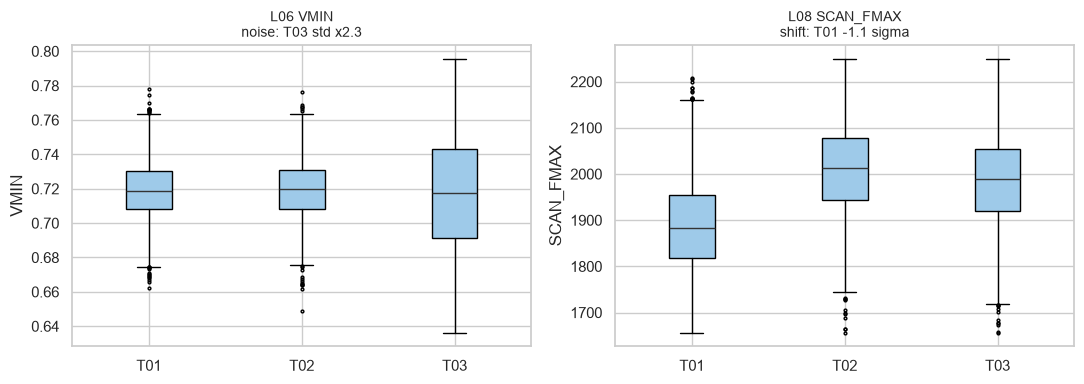

In [9]:
def station_box(ax, lot, test, title):
    sub = first[first["lot_id"] == lot]
    values = np.log(sub[test]) if test in LOG_TESTS else sub[test]
    lo, hi = values.quantile([0.005, 0.995])
    order = sorted(sub["station"].unique())
    groups = [values[sub["station"] == s].dropna().clip(lo, hi) for s in order]
    ax.boxplot(
        groups,
        tick_labels=order,
        patch_artist=True,
        boxprops={"facecolor": "#9ECAE9"},
        medianprops={"color": "#333"},
        flierprops={"markersize": 2},
    )
    ax.set_title(f"{lot} {test}" + (f"\n{title}" if title else ""), fontsize=10)
    ax.set_ylabel(f"ln({test})" if test in LOG_TESTS else test)


panels = []
noise = station_flags[station_flags["kind"] == "noise"]
shift = station_flags[station_flags["kind"] == "shift"]
if len(noise):
    r = noise.sort_values("std_ratio", ascending=False).iloc[0]
    panels.append((r["lot_id"], r["test"], f"noise: {r['station']} std x{r['std_ratio']:.1f}"))
if len(shift):
    r = shift.loc[shift["delta_sigma"].abs().idxmax()]
    panels.append((r["lot_id"], r["test"], f"shift: {r['station']} {r['delta_sigma']:+.1f} sigma"))

fig, axes = plt.subplots(1, max(len(panels), 1), figsize=(5.5 * max(len(panels), 1), 4))
for ax, (lot, test, label) in zip(np.atleast_1d(axes), panels, strict=True):
    station_box(ax, lot, test, label)
save(fig, "c05_station_parametrics.png")

左右两张图对应两种指纹：一台测试机箱体明显变宽（噪声），一台整体平移（偏移）。
这是"硬件问题"在参数分布上的样子，和芯片本身的缺陷不同。

### 整批偏移（工艺）与整体 Cpk

如果某个 **lot** 在**多个独立测试项**上同时偏移，更像整批工艺偏移（快角/慢角），而不是测试问题——
测试问题通常只影响一两个测试项。只要求偏移的测试项个数，不要求符号一致：
快角会表现为速度上升、漏电上升、Vmin 下降。

In [10]:
def lot_effects(first, names):
    rows = []
    for test in names:
        values = scale_values(first[test], test)
        for lot, mask in first.groupby("lot_id").groups.items():
            inside = values.loc[mask].dropna()
            rest = values.drop(index=mask).dropna()
            rows.append(
                {
                    "lot_id": lot,
                    "test": test,
                    "delta_sigma": (inside.median() - rest.median()) / robust_sigma(rest),
                }
            )
    return pd.DataFrame(rows)


def flag_lot_effects(table, min_sigma=0.5, min_tests=3):
    big = table[table["delta_sigma"].abs() >= min_sigma]
    counts = big.groupby("lot_id")["test"].transform("size")
    return big[counts >= min_tests].sort_values(["lot_id", "delta_sigma"]).reset_index(drop=True)


lot_flags = flag_lot_effects(lot_effects(first, cont))
lot_flags.round(3)

,lot_id,test,delta_sigma
0,L07,VMIN,-0.950
1,L07,SCAN_FMAX,0.871
2,L07,IDD_STANDBY,1.116
3,L07,IDD_ACTIVE,1.201


In [11]:
def cpk_table(first, tests):
    """稳健 Cpk（中位数 + MAD）。下限为 0 的量是物理边界，不当作规格下限。"""
    limits = tests.set_index("name")
    row = {}
    for t in [t for t in tests["name"] if limits.loc[t, "unit"] != "cnt"]:
        lo, hi = limits.loc[t, ["lo", "hi"]]
        v = scale_values(first[t], t).dropna()
        if t in LOG_TESTS:
            lo, hi = (np.log(lo) if lo > 0 else np.nan), np.log(hi)
        lo = np.nan if lo == 0 else lo
        mu, sigma = v.median(), robust_sigma(v)
        sides = [
            (hi - mu) if not np.isnan(hi) else np.inf,
            (mu - lo) if not np.isnan(lo) else np.inf,
        ]
        row[t] = min(sides) / (3 * sigma)
    return pd.DataFrame({"all": row}).T.rename_axis("scope")


cpk_table(first, tests).T.round(2)

scope,all
CONT_VDD,12.29
CONT_IO,13.33
IDD_STANDBY,0.75
IDD_ACTIVE,1.18
VREF,1.35
LDO_OUT,1.38
OSC_FREQ,1.31
PLL_LOCK,3.26
ADC_OFFSET,1.37
SCAN_FMAX,0.72


前面整批偏移表里标出的 L07，在多个独立测试项上同时偏移：速度上升、漏电和工作电流上升、Vmin 下降，
正是快角的样子。它的 FPY 最低、复测不恢复，和这个解释一致，应该交给工艺/产品团队，而不是去查测试机。

Cpk 低的测试项，说明规格余量小，是良率损失和测试机间相关性问题最先暴露的地方：
这份数据里漏电（`IDD_STANDBY`）和 `SCAN_FMAX` 最低（约 0.7），其余大多在 1.1 以上。
注意这是**稳健** Cpk（中位数 + MAD），不被致命缺陷的极端读数拉偏。

## 5. 给每个热点一个"指纹"，再给出待验证假设

定位到格子之后，看三件事把原因分开：

1. **哪个测试项在失败**（接触电阻？VMIN？SCAN_FMAX？），与同 lot 其余芯片比较，lift = 倍数；
2. **复测恢复率**：间歇性问题恢复率高，系统性偏移几乎不恢复；
3. **范围**：只出现在某个 site（接触/针卡），还是整台测试机（电源、时序校准）。

输出的假设**只是排查的起点，不是结论**：每一条都要到现场用仪器确认。

In [12]:
def failing_tests(first, cell, names):
    lot = first.loc[cell, "lot_id"].unique()
    rest = first[first["lot_id"].isin(lot) & ~cell]
    inside = first[cell]
    out = pd.DataFrame(
        {
            "fail_rate": [inside[f"fail_{t}"].mean() for t in names],
            "rest_fail_rate": [rest[f"fail_{t}"].mean() for t in names],
        },
        index=pd.Index(names, name="test"),
    )
    out["lift"] = out["fail_rate"] / out["rest_fail_rate"].replace(0, np.nan)
    return out.sort_values("fail_rate", ascending=False).reset_index()


def signature(first, cell, names):
    lot = first.loc[cell, "lot_id"].unique()
    rest = first[first["lot_id"].isin(lot) & ~cell]
    inside = first[cell]
    top = failing_tests(first, cell, names).iloc[0]
    return {
        "dies": int(len(inside)),
        "fpy": float(inside["tester_pass"].mean()),
        "rest_fpy": float(rest["tester_pass"].mean()),
        "top_test": str(top["test"]),
        "top_test_fail_rate": float(top["fail_rate"]),
        "top_test_rest_fail_rate": float(top["rest_fail_rate"]),
        "recovery_rate": float(yield_by(inside.assign(s=1), "s")["recovery_rate"].iloc[0]),
        "rest_recovery_rate": float(yield_by(rest.assign(s=1), "s")["recovery_rate"].iloc[0]),
    }


def hypothesis(sig, site_specific, noisy):
    # 对照组恢复率本身很低（几个百分点），只比倍数不可靠，所以同时要求绝对值：复测至少挽回四分之一
    recovers = (
        sig["recovery_rate"] >= 0.25 and sig["recovery_rate"] >= 3 * sig["rest_recovery_rate"]
    )
    if site_specific and sig["top_test"].startswith("CONT_") and recovers:
        return (
            "单个 site、接触电阻升高、复测大量恢复：像探针/插座接触不良或针卡磨损（类比虚焊）。"
            "验证：看该 site 的接触电阻分布与探针痕迹，换针卡/插座后对比。"
        )
    if noisy:
        return (
            "只有离散度变大、均值不变，复测部分恢复：像该测试机电源或测量噪声变大。"
            "验证：示波器看电源纹波与地弹，接上解耦电容或换电源板后对比。"
        )
    if not recovers:
        return (
            "整台测试机同一测试项系统性偏移、复测不恢复：像时序/校准偏移（edge placement、"
            "strobe）或程序变更。验证：用同一批样片（golden unit）在各测试机上做相关性对比，重新校准。"
        )
    return "复测恢复偏高但特征不典型：先确认接触与环境，再扩大样本。"


def cell_mask(first, lot, station, site):
    m = (first["lot_id"] == lot) & (first["station"] == station)
    return m & (first["site"] == site) if site is not None else m


def find_suspects(first, names, cells, stations, station_flags):
    found, taken = [], set()

    def add(lot, station, site, kind, noisy=False):
        sig = signature(first, cell_mask(first, lot, station, site), names)
        found.append(
            {
                "lot_id": lot,
                "station": station,
                "site": site,
                "kind": kind,
                "signature": sig,
                "hypothesis": hypothesis(sig, site_specific=site is not None, noisy=noisy),
            }
        )
        taken.add((lot, station))

    if len(cells):
        top = cells.iloc[0]
        add(top["lot_id"], top["station"], int(top["site"]), "site hotspot")
    for _, row in stations.iterrows():
        if (row["lot_id"], row["station"]) not in taken:
            add(row["lot_id"], row["station"], None, "station hotspot")
    for _, row in station_flags[station_flags["kind"] == "noise"].iterrows():
        if (row["lot_id"], row["station"]) not in taken:
            add(row["lot_id"], row["station"], None, "noise", noisy=True)
    return found


suspects = find_suspects(first, test_names, cells, stations, station_flags)
pd.DataFrame(
    [
        {"lot": s["lot_id"], "station": s["station"], "site": s["site"], "kind": s["kind"]}
        | s["signature"]
        for s in suspects
    ]
).round(4)

,lot,station,site,kind,dies,fpy,rest_fpy,top_test,top_test_fail_rate,top_test_rest_fail_rate,recovery_rate,rest_recovery_rate
0,L04,T02,3.0,site hotspot,687,0.6638,0.9480,CONT_VDD,0.2751,0.0000,0.5541,0.0558
1,L05,T01,NaN,station hotspot,3594,0.8720,0.9492,SCAN_FMAX,0.0899,0.0069,0.0719,0.0588
2,L08,T01,NaN,station hotspot,3595,0.8729,0.9440,SCAN_FMAX,0.0873,0.0080,0.0702,0.0266
3,L06,T03,NaN,noise,2701,0.9082,0.9339,VMIN,0.0422,0.0000,0.4113,0.0819


In [13]:
for i, s in enumerate(suspects, 1):
    where = f"{s['lot_id']} / {s['station']}" + (f" / site{s['site']}" if s["site"] else "")
    g = s["signature"]
    print(f"线索 {i}（{where}，{s['kind']}）")
    print(
        f"  FPY {g['fpy']:.1%}（同 lot 其余 {g['rest_fpy']:.1%}）；"
        f"主要失败项 {g['top_test']}（{g['top_test_fail_rate']:.1%} vs {g['top_test_rest_fail_rate']:.1%}）；"
        f"复测恢复率 {g['recovery_rate']:.0%}（对照 {g['rest_recovery_rate']:.0%}）"
    )
    print(f"  假设：{s['hypothesis']}\n")

线索 1（L04 / T02 / site3，site hotspot）
  FPY 66.4%（同 lot 其余 94.8%）；主要失败项 CONT_VDD（27.5% vs 0.0%）；复测恢复率 55%（对照 6%）
  假设：单个 site、接触电阻升高、复测大量恢复：像探针/插座接触不良或针卡磨损（类比虚焊）。验证：看该 site 的接触电阻分布与探针痕迹，换针卡/插座后对比。

线索 2（L05 / T01，station hotspot）
  FPY 87.2%（同 lot 其余 94.9%）；主要失败项 SCAN_FMAX（9.0% vs 0.7%）；复测恢复率 7%（对照 6%）
  假设：整台测试机同一测试项系统性偏移、复测不恢复：像时序/校准偏移（edge placement、strobe）或程序变更。验证：用同一批样片（golden unit）在各测试机上做相关性对比，重新校准。

线索 3（L08 / T01，station hotspot）
  FPY 87.3%（同 lot 其余 94.4%）；主要失败项 SCAN_FMAX（8.7% vs 0.8%）；复测恢复率 7%（对照 3%）
  假设：整台测试机同一测试项系统性偏移、复测不恢复：像时序/校准偏移（edge placement、strobe）或程序变更。验证：用同一批样片（golden unit）在各测试机上做相关性对比，重新校准。

线索 4（L06 / T03，noise）
  FPY 90.8%（同 lot 其余 93.4%）；主要失败项 VMIN（4.2% vs 0.0%）；复测恢复率 41%（对照 8%）
  假设：只有离散度变大、均值不变，复测部分恢复：像该测试机电源或测量噪声变大。验证：示波器看电源纹波与地弹，接上解耦电容或换电源板后对比。



读法：**四个线索，三种不同的指纹**：

- 单个 site 的接触问题：接触测试项失败、复测恢复率高（线索 1）；
- 整台测试机的系统性偏移：`SCAN_FMAX` 整体偏移、复测几乎不恢复（线索 2、3）；
- 电源噪声：只有离散度变大、均值不变，复测部分恢复（线索 4）。

它们在"良率低"这一个现象下面，需要的排查动作完全不同，这就是不能只看良率的原因。

## 6. 晶圆图：径向损失与空间集群

两种空间模式，成因不同：

- **径向（边缘）良率损失**：工艺均匀性问题，用**等面积**分环比较（每环芯片数大致相同，所以各环良率可直接比较）；
- **失败芯片的空间集群**：划伤、局部污染。

集群的判定不能只看"有多大"：失败率高的晶圆随机也会拼出大块。
所以用**置换检验**——在同一环、同一 site 内随机打乱失败标签（保留径向趋势和 site 效应），
看真实的最大集群是否超出随机预期。

,ring,dies,fpy
0,1,15401,0.9371
1,2,15314,0.9377
2,3,15317,0.9393
3,4,15329,0.9162
4,5,10546,0.8837


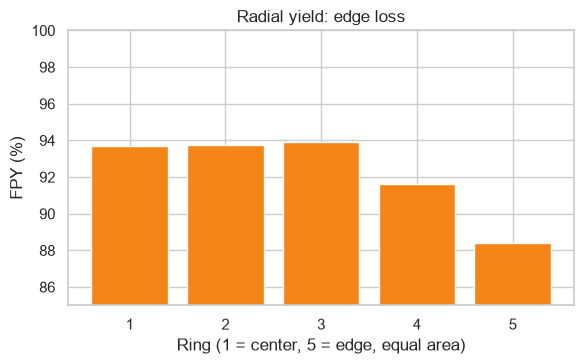

In [14]:
def add_radius(first):
    radius = np.hypot(first["x"], first["y"])
    r = radius / (radius.max() + 0.5)
    ring = np.minimum((r**2 * 5).astype(int), 4) + 1
    return first.assign(r=r, ring=ring)


radial = (
    add_radius(first)
    .groupby("ring")
    .agg(dies=("x", "size"), fpy=("tester_pass", "mean"))
    .reset_index()
)
display(radial.round(4))

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(radial["ring"].astype(str), radial["fpy"] * 100, color="#F58518")
ax.set_ylim(min(radial["fpy"].min() * 100 - 3, 85), 100)
ax.set_xlabel("Ring (1 = center, 5 = edge, equal area)")
ax.set_ylabel("FPY (%)")
ax.set_title("Radial yield: edge loss")
save(fig, "c04_radial_yield.png")

In [15]:
EIGHT_NEIGHBORS = np.ones((3, 3), dtype=int)


def largest_cluster(grid):
    labels, count = ndimage.label(grid, structure=EIGHT_NEIGHBORS)
    return int(np.bincount(labels.ravel())[1:].max()) if count else 0


def scan_wafers(first, n_perm=500, min_size=8, seed=0):
    framed = add_radius(first)
    rng = np.random.default_rng(seed)
    extent = int(max(framed["x"].abs().max(), framed["y"].abs().max()))
    side = 2 * extent + 1
    rows = []
    for (lot, wafer), g in framed.groupby(["lot_id", "wafer_id"]):
        xs, ys = (g["x"] + extent).to_numpy(), (g["y"] + extent).to_numpy()
        fail = ~g["tester_pass"].to_numpy()
        strata = (g["ring"] * 10 + g["site"]).to_numpy()
        groups = [np.flatnonzero(strata == s) for s in np.unique(strata)]

        def largest(flags, xs=xs, ys=ys):
            grid = np.zeros((side, side), dtype=bool)
            grid[ys, xs] = flags
            return largest_cluster(grid)

        observed = largest(fail)
        perm = np.empty(n_perm, dtype=int)
        for k in range(n_perm):
            shuffled = fail.copy()
            for idx in groups:
                shuffled[idx] = rng.permutation(fail[idx])
            perm[k] = largest(shuffled)
        p_value = (1 + int((perm >= observed).sum())) / (n_perm + 1)
        rows.append((lot, wafer, int(fail.sum()), observed, float(perm.mean()), p_value))
    table = pd.DataFrame(
        rows,
        columns=["lot_id", "wafer_id", "fails", "largest_cluster", "expected_cluster", "perm_p"],
    )
    table["flagged"] = (table["largest_cluster"] >= min_size) & (
        table["perm_p"] <= 1 / (n_perm + 1)
    )
    return table.sort_values(
        ["flagged", "perm_p", "largest_cluster"], ascending=[False, True, False]
    )


wafers = scan_wafers(first)
clusters = wafers[wafers["flagged"]]
print(f"{len(wafers)} 片晶圆里 {len(clusters)} 片有显著集群（置换 500 次，最小集群 8 颗）")
wafers.head(5).round(4)

80 片晶圆里 1 片有显著集群（置换 500 次，最小集群 8 颗）


,lot_id,wafer_id,fails,largest_cluster,expected_cluster,perm_p,flagged
26,L03,07,104,61,7.330,0.0020,True
34,L04,05,110,11,5.880,0.0180,False
24,L03,05,38,5,2.706,0.0220,False
20,L03,01,42,5,2.966,0.0399,False
33,L04,04,47,5,3.092,0.0619,False


`perm_p` 的下限是 1/501：真实集群比 500 次随机打乱里的任何一次都大，才会被标出。
`expected_cluster` 是随机打乱下的平均最大集群，真实值远超它才说明不是随机拼出来的。
上面的径向表里，最外环的 FPY 明显低于内三环，是边缘良率损失；
集群只有一片晶圆被标出，真实最大集群比随机预期大一个数量级。

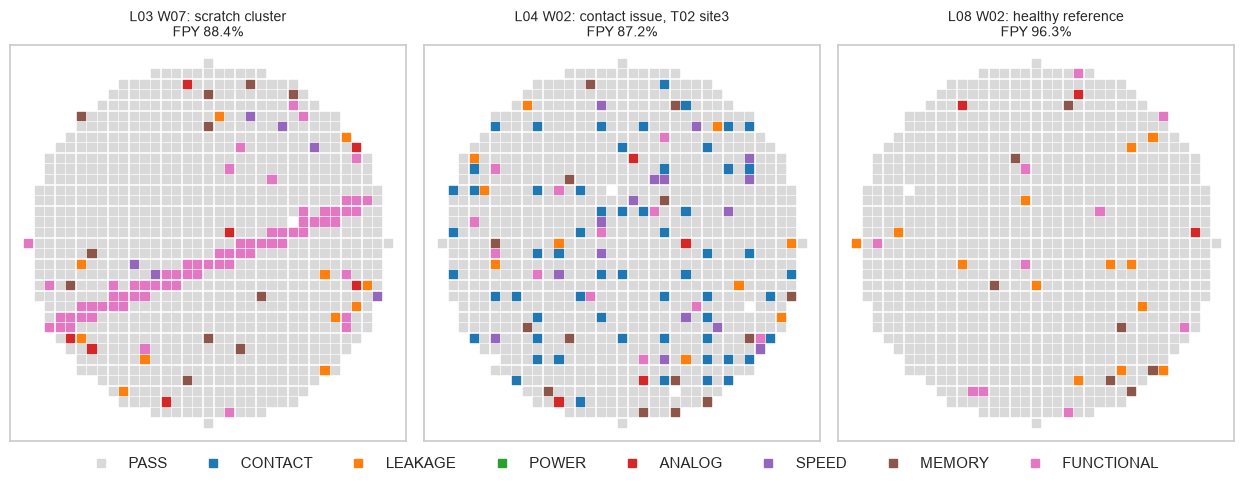

In [16]:
PASS_COLOR = "#D9D9D9"


def wafer_ax(ax, wafer_df, title, colors):
    color = [
        PASS_COLOR if ok else colors[b]
        for ok, b in zip(wafer_df["tester_pass"], wafer_df["hbin"], strict=True)
    ]
    ax.scatter(wafer_df["x"], wafer_df["y"], c=color, marker="s", s=34)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])


picks = []
if len(clusters):
    c = clusters.iloc[0]
    picks.append((c["lot_id"], c["wafer_id"], "scratch cluster"))
site_hot = [s for s in suspects if s["kind"] == "site hotspot"]
if site_hot:
    s = site_hot[0]
    sub = first[(first["lot_id"] == s["lot_id"]) & (first["station"] == s["station"])]
    wafer_id = sub.groupby("wafer_id")["tester_pass"].mean().idxmin()
    picks.append((s["lot_id"], wafer_id, f"contact issue, {s['station']} site{s['site']}"))
best = first.groupby(["lot_id", "wafer_id"])["tester_pass"].mean().idxmax()
picks.append((*best, "healthy reference"))

fail_bins = sorted(first.loc[~first["tester_pass"], "hbin"].unique())
colors = dict(zip(fail_bins, sns.color_palette("tab10", len(fail_bins)), strict=True))
bin_names = first.drop_duplicates("hbin").set_index("hbin")["hbin_name"]
fig, axes = plt.subplots(1, len(picks), figsize=(4.2 * len(picks), 4.8))
for ax, (lot, wafer_id, label) in zip(np.atleast_1d(axes), picks, strict=True):
    w = first[(first["lot_id"] == lot) & (first["wafer_id"] == wafer_id)]
    wafer_ax(ax, w, f"{lot} W{wafer_id}: {label}\nFPY {w['tester_pass'].mean():.1%}", colors)
handles = [plt.Line2D([], [], marker="s", ls="", color=PASS_COLOR, label="PASS")]
handles += [
    plt.Line2D([], [], marker="s", ls="", color=c, label=bin_names[b]) for b, c in colors.items()
]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False)
save(fig, "c03_wafer_maps.png")

三张图对比：划伤集群（失败芯片连成一条带）、接触不良的 site（失败零散分布、以接触类为主，
在空间上不连成片）、正常对照。配色按 bin 固定，同一个失败类型在每张图里颜色一致。
两种"失败多"的晶圆，成因和处理方式完全不同：前者查工艺和搬运，后者查探针和插座。

## 7. 保存线索摘要

这里先写出前半部分（整体良率、线索、集群晶圆、整批偏移的 lot）；
Notebook 03 会读取这个文件，补全 PAT、测试顺序和仿真评估三部分。

In [17]:
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 6)
    if isinstance(o, np.integer):
        return int(o)
    return o


summary = {
    "overall": overall_yield,
    "suspects": [
        {"lot": s["lot_id"], "station": s["station"], "site": s["site"], "kind": s["kind"]}
        | s["signature"]
        for s in suspects
    ],
    "clusters": clusters[["lot_id", "wafer_id", "largest_cluster"]].to_dict("records"),
    "lot_process_shift": sorted(lot_flags["lot_id"].unique()),
}
SUMMARY.write_text(json.dumps(clean(summary), ensure_ascii=False, indent=2))
print(f"saved -> {SUMMARY.relative_to(ROOT)}（{', '.join(summary)}）")

saved -> data/processed/chip_summary.json（overall, suspects, clusters, lot_process_shift）


## 局限性

- 数据是**模拟的**：缺陷类型、分布和各测试机的行为都是按教学需要设定的，不代表任何真实芯片或产线。
- 同 lot 内对照假设芯片被**随机**分到各测试机和 site；真实产线如果按晶圆顺序固定分配，
  测试机之间的差异会和晶圆差异混在一起，需要用 golden unit 重复测来拆开。
- 参数偏移阈值（0.6σ、σ 放大 1.5 倍）是在这份数据上定的，换了产品需要重新标定。
- 置换检验保留了径向和 site 效应，但没有保留晶圆上更细的空间自相关，对非常平滑的渐变图案会偏敏感。
- 假设只是排查的起点，每一条都需要在现场用示波器、万用表等仪器确认，不能当结论。